<a href="https://colab.research.google.com/github/Savithmee/Deep-Learning-CW-/blob/Omethmee/EntailmentModelling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install transformers==4.45.2 sentencepiece psutil
import torch, transformers, sentencepiece
print("torch", torch.__version__, "| transformers", transformers.__version__, "| GPU available:", torch.cuda.is_available())
N_FACTS = None   # e.g. 100 for a quick test; None = whole dev set

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 38.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 22.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 76.6 MB/s  0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.33.0
    Uninstalling huggingface_hub-1.33.0:
      Successfully uninstalled huggingface_hub-1.33.0
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.23.3
    Uninstalling tokenizers-0.23.3:
      Successfully uninstalled tokenizers-0.23.3
  Attempting uninstall: transformers
    Found existing installation: transformers 5.20.2
    Uninstalling transformers-5.20.2:
      Successfully uninstalled transformers-5.20.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [transformers]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency confli

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
DATA_DIR = '/content/drive/MyDrive/data'
LABELS = f'{DATA_DIR}/dev_labeled_ChatGPT.jsonl'
PASSAGES = f'{DATA_DIR}/passages_bm25_ChatGPT_humfacts.jsonl'

print(os.listdir(DATA_DIR))
assert os.path.exists(LABELS) and os.path.exists(PASSAGES), "Files not found - check the file names printed above"
print(LABELS); print(PASSAGES)

Mounted at /content/drive
['FACTSCORE-LICENSE.txt', 'dev_labeled_ChatGPT.jsonl', 'passages_bm25_ChatGPT_humfacts.jsonl']
/content/drive/MyDrive/data/dev_labeled_ChatGPT.jsonl
/content/drive/MyDrive/data/passages_bm25_ChatGPT_humfacts.jsonl


In [3]:
import json, re, gc, time, os
import numpy as np
from typing import List
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

class FactExample(object):
    def __init__(self, fact, passages, label):
        self.fact, self.passages, self.label = fact, passages, label

def read_passages(path):
    d = {}
    with open(path) as f:
        for line in f:
            o = json.loads(line)
            d[o["sent"]] = o["passages"]
    return d

def read_fact_examples(path, fact_to_passage):
    ex = []
    with open(path) as f:
        for line in f:
            o = json.loads(line)
            if o["annotations"] is None: continue
            for sent in o["annotations"]:
                if sent["human-atomic-facts"] is None: continue
                for fact in sent["human-atomic-facts"]:
                    if fact["text"] in fact_to_passage:
                        ex.append(FactExample(fact["text"], fact_to_passage[fact["text"]], fact["label"]))
    return ex

examples = read_fact_examples(LABELS, read_passages(PASSAGES))
if N_FACTS: examples = examples[:N_FACTS]
gold = np.array([1 if (e.label == "S") else 0 for e in examples])   # IR is mapped to NS
print(len(examples), "facts |", gold.sum(), "S /", (1 - gold).sum(), "NS | majority-class accuracy =", round(max(gold.mean(), 1 - gold.mean()), 4))

221 facts | 112 S / 109 NS | majority-class accuracy = 0.5068


In [4]:
# PERSON D: passage preparation and pruning (pasted)
import re, html, unicodedata
from typing import List, Dict, Optional

USE_D = True    # False = use the simple stand-ins in Cell 4 instead of D's module

STOPWORDS = set("""a about above after again against all am an and any are as at be because been before being
below between both but by can did do does doing down during each few for from further had has have having he her
here hers herself him himself his how i if in into is it its itself just me more most my myself no nor not now of
off on once only or other our ours ourselves out over own same she should so some such than that the their theirs
them themselves then there these they this those through to too under until up very was we were what when where
which while who whom why will with you your yours yourself yourselves also""".split())

DEFAULT_CFG = dict(
    splitter="regex",        # tags | naive | regex | nltk | spacy
    min_words=3,
    max_words=100,
    window=1,                # 1 = single sentences, 2/3 = windows, 10**6 = whole passage
    stride=1,
    title="none",            # none | all | pronoun
    prune_thr=None,          # None = no pruning
    min_keep=1,
    max_keep=None,
    order="window_then_prune",   # or prune_then_window
)

# cleaning
_TAG = re.compile(r"<[^>]+>")
_CITE = re.compile(r"\[\d+\]|\[citation needed\]", re.I)

def clean_text(text: str, title: Optional[str] = None) -> str:
    t = html.unescape(text)
    t = unicodedata.normalize("NFKC", t)
    t = _CITE.sub(" ", t)
    t = _TAG.sub(" ", t)
    t = re.sub(r"\s+", " ", t).strip()
    if title and t.startswith(title + " " + title):
        t = t[len(title) + 1:]
    return t

# sentence splitting
_REGEX_SPLIT = re.compile(r"(?<=[.!?])\s+(?=[\"'(A-Z0-9])")
_SPACY = None
_NLTK_OK = None

def _split_text(segments: List[str], splitter: str) -> List[str]:
    global _SPACY, _NLTK_OK
    if splitter == "tags":
        return segments
    out = []
    if splitter == "naive":
        for s in segments:
            parts = s.split(". ")
            out += [p if p.endswith(".") or i == len(parts) - 1 else p + "." for i, p in enumerate(parts)]
    elif splitter == "regex":
        for s in segments:
            out += _REGEX_SPLIT.split(s)
    elif splitter == "nltk":
        import nltk
        from nltk.tokenize import sent_tokenize
        if _NLTK_OK is None:
            nltk.download("punkt_tab", quiet=True)
            nltk.download("punkt", quiet=True)
            _NLTK_OK = True
        for s in segments:
            out += sent_tokenize(s)
    elif splitter == "spacy":
        if _SPACY is None:
            import spacy
            _SPACY = spacy.blank("en")
            _SPACY.add_pipe("sentencizer")
        for doc in _SPACY.pipe(segments):
            out += [x.text for x in doc.sents]
    else:
        raise ValueError("unknown splitter " + splitter)
    return out

def _chunk(text: str, max_words: Optional[int]) -> List[str]:
    words = text.split()
    if not max_words or len(words) <= max_words:
        return [text]
    pieces, cur = [], []
    for part in re.split(r"(?<=;)\s+", text):
        pw = part.split()
        if cur and len(cur) + len(pw) > max_words:
            pieces.append(" ".join(cur)); cur = []
        cur += pw
    if cur:
        pieces.append(" ".join(cur))
    out = []
    for p in pieces:
        w = p.split()
        out += [" ".join(w[i:i + max_words]) for i in range(0, len(w), max_words)]
    return out

def sentence_units(passages: List[dict], splitter="regex", min_words=3, max_words=100) -> List[Dict]:
    units, seen = [], set()
    for pid, p in enumerate(passages):
        title = p.get("title", "")
        segs = [clean_text(s, title) for s in re.split(r"</?s>", p["text"])]
        segs = [s for s in segs if s]
        sid = 0
        for sent in _split_text(segs, splitter):
            for piece in _chunk(sent.strip(), max_words):
                if len(piece.split()) < min_words:
                    continue
                key = piece.lower()
                if key in seen:
                    continue
                seen.add(key)
                units.append(dict(title=title, pid=pid, sid=sid, text=piece))
                sid += 1
    return units

def _windows(units: List[Dict], window: int, stride: int) -> List[Dict]:
    if window <= 1:
        return [dict(title=u["title"], text=u["text"]) for u in units]
    out, seen = [], set()
    pids = sorted({u["pid"] for u in units})
    for pid in pids:
        g = [u for u in units if u["pid"] == pid]
        n = len(g)
        starts = [0] if window >= n else list(range(0, n - window + 1, max(1, stride)))
        if window < n and starts[-1] != n - window:
            starts.append(n - window)
        for s in starts:
            text = " ".join(u["text"] for u in g[s:s + window])
            if text.lower() not in seen:
                seen.add(text.lower())
                out.append(dict(title=g[0]["title"], text=text))
    return out

def candidates(passages: List[dict], cfg: Optional[dict] = None) -> List[Dict]:
    c = {**DEFAULT_CFG, **(cfg or {})}
    units = sentence_units(passages, c["splitter"], c["min_words"], c["max_words"])
    return _windows(units, c["window"], c["stride"])

# overlap + pruning
def content_tokens(text: str) -> set:
    return {w for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOPWORDS}

def overlap_score(fact_tokens: set, text: str) -> float:
    if not fact_tokens:
        return 1.0
    return len(fact_tokens & content_tokens(text)) / len(fact_tokens)

def select(scores: List[float], min_overlap: float, min_keep: int = 1, max_keep: Optional[int] = None) -> List[int]:
    if not scores:
        return []
    keep = [i for i, s in enumerate(scores) if s >= min_overlap]
    if max_keep is not None and len(keep) > max_keep:
        keep = sorted(sorted(keep, key=lambda i: -scores[i])[:max_keep])
    if not keep:
        keep = sorted(sorted(range(len(scores)), key=lambda i: -scores[i])[:max(1, min_keep)])
    return keep

def prune(fact: str, sentences: List[str], min_overlap: float = 0.1,
          min_keep: int = 1, max_keep: Optional[int] = None) -> List[str]:
    ft = content_tokens(fact)
    scores = [overlap_score(ft, s) for s in sentences]
    return [sentences[i] for i in select(scores, min_overlap, min_keep, max_keep)]

# titles + full pipeline
_PRON = re.compile(r"^(He|She|They|His|Her|Their|It|Its)\b")

def _with_title(title: str, text: str, mode: str) -> str:
    if mode == "all" or (mode == "pronoun" and _PRON.match(text)):
        return f"{title}: {text}"
    return text

def make_premises(fact: str, passages: List[dict], cfg: Optional[dict] = None) -> List[Dict]:
    c = {**DEFAULT_CFG, **(cfg or {})}
    ft = content_tokens(fact)
    thr = c["prune_thr"]
    if c["order"] == "prune_then_window" and c["window"] > 1 and thr is not None:
        units = sentence_units(passages, c["splitter"], c["min_words"], c["max_words"])
        sc = [overlap_score(ft, u["text"]) for u in units]
        items, seen = [], set()
        for i in select(sc, thr, c["min_keep"], c["max_keep"]):
            u = units[i]
            grp = [v for v in units if v["pid"] == u["pid"] and u["sid"] <= v["sid"] < u["sid"] + c["window"]]
            plain = " ".join(v["text"] for v in grp)
            if plain.lower() not in seen:
                seen.add(plain.lower())
                items.append(dict(title=u["title"], text=plain))
        cands = items
        scores = [overlap_score(ft, x["text"]) for x in cands]
        keep = list(range(len(cands)))
    else:
        cands = candidates(passages, c)
        scores = [overlap_score(ft, x["text"]) for x in cands]
        keep = list(range(len(cands))) if thr is None else select(scores, thr, c["min_keep"], c["max_keep"])
    return [dict(text=_with_title(cands[i]["title"], cands[i]["text"], c["title"]),
                 plain=cands[i]["text"], overlap=scores[i]) for i in keep]

def split_passages(passages: List[dict], **cfg) -> List[str]:
    c = {**DEFAULT_CFG, **cfg}
    return [_with_title(x["title"], x["text"], c["title"]) for x in candidates(passages, c)]
# end of Person D's code
print("Passage preparation module loaded | USE_D =", USE_D, "| config:", {k: DEFAULT_CFG[k] for k in ("splitter", "min_words", "max_words", "window", "title")})

Passage preparation module loaded | USE_D = True | config: {'splitter': 'regex', 'min_words': 3, 'max_words': 100, 'window': 1, 'title': 'none'}


In [5]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
CUDA = torch.cuda.is_available()
MODEL_NAME = "MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
hf_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)
if CUDA: hf_model.to("cuda")
hf_model.eval()
print("label order from config:", hf_model.config.id2label)

class EntailmentModel(object):
    def __init__(self, model, tokenizer, cuda=False, max_length=512, cleanup=True):
        self.model, self.tokenizer, self.cuda = model, tokenizer, cuda
        self.max_length, self.cleanup = max_length, cleanup
        id2label = {int(k): v.lower() for k, v in model.config.id2label.items()}
        self.ent_idx = next(i for i, l in id2label.items() if l.startswith("entail"))
        self.neu_idx = next(i for i, l in id2label.items() if l.startswith("neutral"))
        self.con_idx = next(i for i, l in id2label.items() if l.startswith("contra"))

    def check_entailment(self, premise, hypothesis):
        # premise: str or list of str. Returns (n,3) array: [entailment, neutral, contradiction]
        premises = [premise] if isinstance(premise, str) else list(premise)
        with torch.no_grad():
            inputs = self.tokenizer(premises, [hypothesis] * len(premises), return_tensors="pt",
                                    truncation=True, max_length=self.max_length, padding=True)
            if self.cuda:
                inputs = {k: v.to("cuda") for k, v in inputs.items()}
            outputs = self.model(**inputs)
            logits = outputs.logits
            probs = torch.softmax(logits, dim=-1).cpu().numpy()
        probs = probs[:, [self.ent_idx, self.neu_idx, self.con_idx]]
        if self.cleanup:
            del inputs, outputs, logits
            gc.collect()
            if self.cuda: torch.cuda.empty_cache()
        return probs

em = EntailmentModel(hf_model, tokenizer, CUDA)

# ---- simple stand-ins (prefixed sa_ so they never clash with Person D's functions); used only when USE_D = False ----
def sa_clean(t):
    t = re.sub(r"<[^>]+>", " ", t)
    return re.sub(r"\s+", " ", t).strip()

def sa_split(text):
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+|\n+", text) if s.strip()]

def sa_overlap(fact, sentence):
    f = set(re.findall(r"[a-z0-9]+", fact.lower()))
    return len(f & set(re.findall(r"[a-z0-9]+", sentence.lower()))) / len(f) if f else 0.0

# how each input format is built with Person D's module
D_MODES = {
    "sent":       {"window": 1, "title": "none"},       # single sentences
    "window2":    {"window": 2, "title": "none"},       # 2-sentence windows
    "title":      {"window": 1, "title": "all"},        # "Title: sentence"
    "title_pron": {"window": 1, "title": "pronoun"},    # title only on pronoun-led sentences
}
MODES = ["sent", "window2", "title"] + (["title_pron"] if USE_D else [])

def make_units(fact, passages, mode="sent"):
    # returns list of (premise_text, overlap_with_fact); overlap is scored on the plain text, without the title prefix
    if USE_D:
        cfg = {**DEFAULT_CFG, **D_MODES[mode]}
        ft = content_tokens(fact)
        return [(_with_title(x["title"], x["text"], cfg["title"]), overlap_score(ft, x["text"]))
                for x in candidates(passages, cfg)]
    units = []
    for p in passages:
        sents = [sa_clean(s) for s in sa_split(p["text"])]
        sents = [s for s in sents if s]
        if mode == "window2":
            pieces = [sents[0]] if len(sents) == 1 else [sents[i] + " " + sents[i + 1] for i in range(len(sents) - 1)]
        else:
            pieces = sents
        for s in pieces:
            prem = (p["title"] + ": " + s) if mode.startswith("title") else s
            units.append((prem, sa_overlap(fact, s)))
    return units

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/369M [00:00<?, ?B/s]

label order from config: {0: 'entailment', 1: 'neutral', 2: 'contradiction'}


In [6]:
def sync():
    if CUDA: torch.cuda.synchronize()

def build_cache(exs, mode="sent", max_length=512, batch=32, desc=""):
    em.max_length = max_length
    cache, pairs = [], 0
    sync(); t0 = time.time()
    for ex in tqdm(exs, desc=desc or mode):
        units = make_units(ex.fact, ex.passages, mode)
        ov = np.array([u[1] for u in units])
        probs = np.zeros((0, 3))
        if units:
            probs = np.concatenate([em.check_entailment([u[0] for u in units[i:i + batch]], ex.fact)
                                    for i in range(0, len(units), batch)])
        pairs += len(units)
        cache.append(dict(ov=ov, probs=probs))
    sync()
    em.max_length = 512
    return dict(cache=cache, seconds=time.time() - t0, pairs=pairs)

caches = {}
caches["sent"] = build_cache(examples, "sent")
print(f"sentence-level pass: {caches['sent']['pairs']} pairs, {caches['sent']['seconds']:.0f}s")

sent:   0%|          | 0/221 [00:00<?, ?it/s]

sentence-level pass: 5242 pairs, 83s


In [7]:
def scores(cache, strategy="p_ent", agg="max", min_ov=0.0, topk=None):
    out = []
    for c in cache:
        idx = np.where(c["ov"] >= min_ov)[0]
        if topk and len(idx) > topk:
            idx = idx[np.argsort(-c["ov"][idx])[:topk]]
        if len(idx) == 0 and USE_D and len(c["ov"]) > 0:
            idx = np.array([int(np.argmax(c["ov"]))])      # same fallback as D's prune: keep the best sentence
        if len(idx) == 0:
            out.append(-np.inf); continue
        p = c["probs"][idx]
        if strategy == "argmax":
            out.append(float((p.argmax(1) == 0).any())); continue
        v = p[:, 0] if strategy == "p_ent" else p[:, 0] - p[:, 2]
        if agg == "max": out.append(v.max())
        elif agg == "top2": out.append(np.sort(v)[-2:].mean())
        elif agg == "mean": out.append(v.mean())
    return np.array(out)

def grid_for(strategy):
    return np.round(np.arange(-1, 1, 0.02), 2) if strategy == "ent_minus_con" else np.round(np.arange(0, 1, 0.01), 2)

def tune(s, strategy, k=5):
    grid = grid_for(strategy)
    accs = np.array([((s > t) == gold).mean() for t in grid])
    sm = np.convolve(accs, np.ones(2 * k + 1) / (2 * k + 1), mode="same")
    idx = np.arange(k, len(grid) - k)
    flat = idx[sm[idx].argmax()]
    return dict(grid=grid, accs=accs, peak_t=grid[accs.argmax()], peak_acc=accs.max(), flat_t=grid[flat], flat_acc=accs[flat])

def f1s(pred, g=None):
    g = gold if g is None else g
    out = []
    for cls in (1, 0):
        tp = ((pred == cls) & (g == cls)).sum(); fp = ((pred == cls) & (g != cls)).sum(); fn = ((pred != cls) & (g == cls)).sum()
        pr = tp / (tp + fp) if tp + fp else 0; rc = tp / (tp + fn) if tp + fn else 0
        out.append(2 * pr * rc / (pr + rc) if pr + rc else 0)
    return out   # [F1_S, F1_NS]

def retention(cache, min_ov, topk=None):
    kept = []
    for c in cache:
        n = (c["ov"] >= min_ov).sum()
        kept.append(min(n, topk) if topk else n)
    kept = np.array(kept)
    return (kept[gold == 1] > 0).mean() * 100, kept.mean(), kept.sum()

In [8]:
C = caches["sent"]["cache"]
rows = []
s = scores(C, "argmax"); pred = (s > 0.5).astype(int)
rows.append(("argmax == entailment", "-", (pred == gold).mean(), *f1s(pred)))
E1 = {}
for st in ["p_ent", "ent_minus_con"]:
    s = scores(C, st); r = tune(s, st); E1[st] = r
    pred = (s > r["flat_t"]).astype(int)
    rows.append((st + " > t (flat t)", r["flat_t"], (pred == gold).mean(), *f1s(pred)))
    rows.append((st + " > t (peak t)", r["peak_t"], r["peak_acc"], *f1s((s > r["peak_t"]).astype(int))))
print(f"{'strategy':<30}{'t':>7}{'acc':>9}{'F1_S':>8}{'F1_NS':>8}")
for n, t, a, fs, fn in rows:
    print(f"{n:<30}{str(t):>7}{a:>9.4f}{fs:>8.4f}{fn:>8.4f}")

strategy                            t      acc    F1_S   F1_NS
argmax == entailment                -   0.8054  0.7943  0.8155
p_ent > t (flat t)               0.71   0.8100  0.7879  0.8279
p_ent > t (peak t)                0.7   0.8145  0.7940  0.8313
ent_minus_con > t (flat t)        0.2   0.8190  0.8165  0.8214
ent_minus_con > t (peak t)        0.2   0.8190  0.8165  0.8214


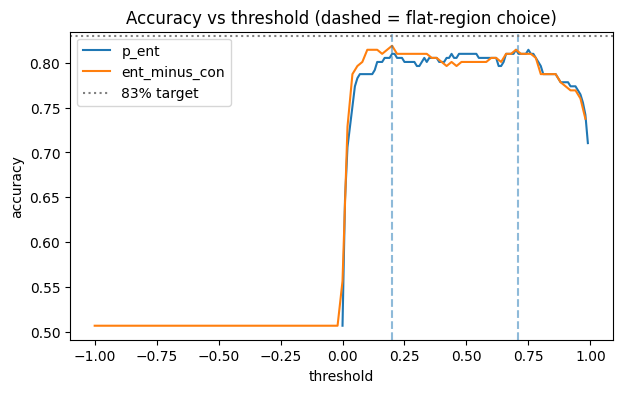

p_ent: 5-fold CV acc = 0.7964 +- 0.0477 | full-dev acc at flat t = 0.8100 | gap = +0.0136
ent_minus_con: 5-fold CV acc = 0.8055 +- 0.0420 | full-dev acc at flat t = 0.8190 | gap = +0.0135


In [9]:
plt.figure(figsize=(7, 4))
for st, r in E1.items():
    plt.plot(r["grid"], r["accs"], label=st)
    plt.axvline(r["flat_t"], ls="--", alpha=.5)
plt.axhline(0.83, color="gray", ls=":", label="83% target")
plt.xlabel("threshold"); plt.ylabel("accuracy"); plt.legend(); plt.title("Accuracy vs threshold (dashed = flat-region choice)")
plt.show()

def cv_gap(strategy, cache, agg="max", min_ov=0.0, folds=5, seed=0):
    s = scores(cache, strategy, agg, min_ov)
    rng = np.random.RandomState(seed); perm = rng.permutation(len(s)); parts = np.array_split(perm, folds)
    grid = grid_for(strategy); accs_cv = []
    for i in range(folds):
        te = parts[i]; tr = np.concatenate([parts[j] for j in range(folds) if j != i])
        a_tr = np.array([((s[tr] > t) == gold[tr]).mean() for t in grid])
        k = 5; sm = np.convolve(a_tr, np.ones(2 * k + 1) / (2 * k + 1), mode="same")
        t_best = grid[k:-k][sm[k:-k].argmax()]
        accs_cv.append(((s[te] > t_best) == gold[te]).mean())
    return np.mean(accs_cv), np.std(accs_cv)

for st in ["p_ent", "ent_minus_con"]:
    m, sd = cv_gap(st, C)
    print(f"{st}: 5-fold CV acc = {m:.4f} +- {sd:.4f} | full-dev acc at flat t = {E1[st]['flat_acc']:.4f} | gap = {E1[st]['flat_acc'] - m:+.4f}")